In [1]:
from pathlib import Path
import json

import numpy as np
import matplotlib.pyplot as plt

from PIL import Image, ImageDraw

# Dataset root directory
DATASET_DIR = Path("dataset")

# Dataset splits
TRAIN_DIR = DATASET_DIR / "train"
VALID_DIR = DATASET_DIR / "valid"
TEST_DIR = DATASET_DIR / "test"

# COCO annotation files
TRAIN_ANNOTATIONS = TRAIN_DIR / "_annotations.coco.json"
VALID_ANNOTATIONS = VALID_DIR / "_annotations.coco.json"
TEST_ANNOTATIONS = TEST_DIR / "_annotations.coco.json"

# Check dataset paths
print("Working directory:", Path.cwd())
print("Training dataset found:", TRAIN_ANNOTATIONS.exists())
print("Validation dataset found:", VALID_ANNOTATIONS.exists())
print("Test dataset found:", TEST_ANNOTATIONS.exists())

Working directory: c:\Scuola\TerzoAnno\ComputerVision\Progetto
Training dataset found: True
Validation dataset found: True
Test dataset found: True


In [2]:
# Load training annotations
with open(TRAIN_ANNOTATIONS, "r") as f:
    train_data = json.load(f)

# Extract images and annotations
images = train_data["images"]
annotations = train_data["annotations"]

print(f"Number of images: {len(images)}")
print(f"Number of annotations: {len(annotations)}")

Number of images: 1502
Number of annotations: 1502


In [3]:
def create_binary_mask(image_info, annotations):
    """
    Create a binary segmentation mask from COCO polygon annotations.

    Args:
        image_info: Dictionary containing image metadata.
        annotations: List of annotations associated with the image.

    Returns:
        Binary mask as a NumPy array (0 = background, 1 = annotated region).
    """

    width = image_info["width"]
    height = image_info["height"]

    # Create an empty black mask
    mask = Image.new("L", (width, height), 0)
    draw = ImageDraw.Draw(mask)

    # Draw all annotated polygons
    for annotation in annotations:
        for polygon in annotation["segmentation"]:

            points = [
                (polygon[i], polygon[i + 1])
                for i in range(0, len(polygon), 2)
            ]

            draw.polygon(points, fill=1)

    return np.array(mask, dtype=np.uint8)

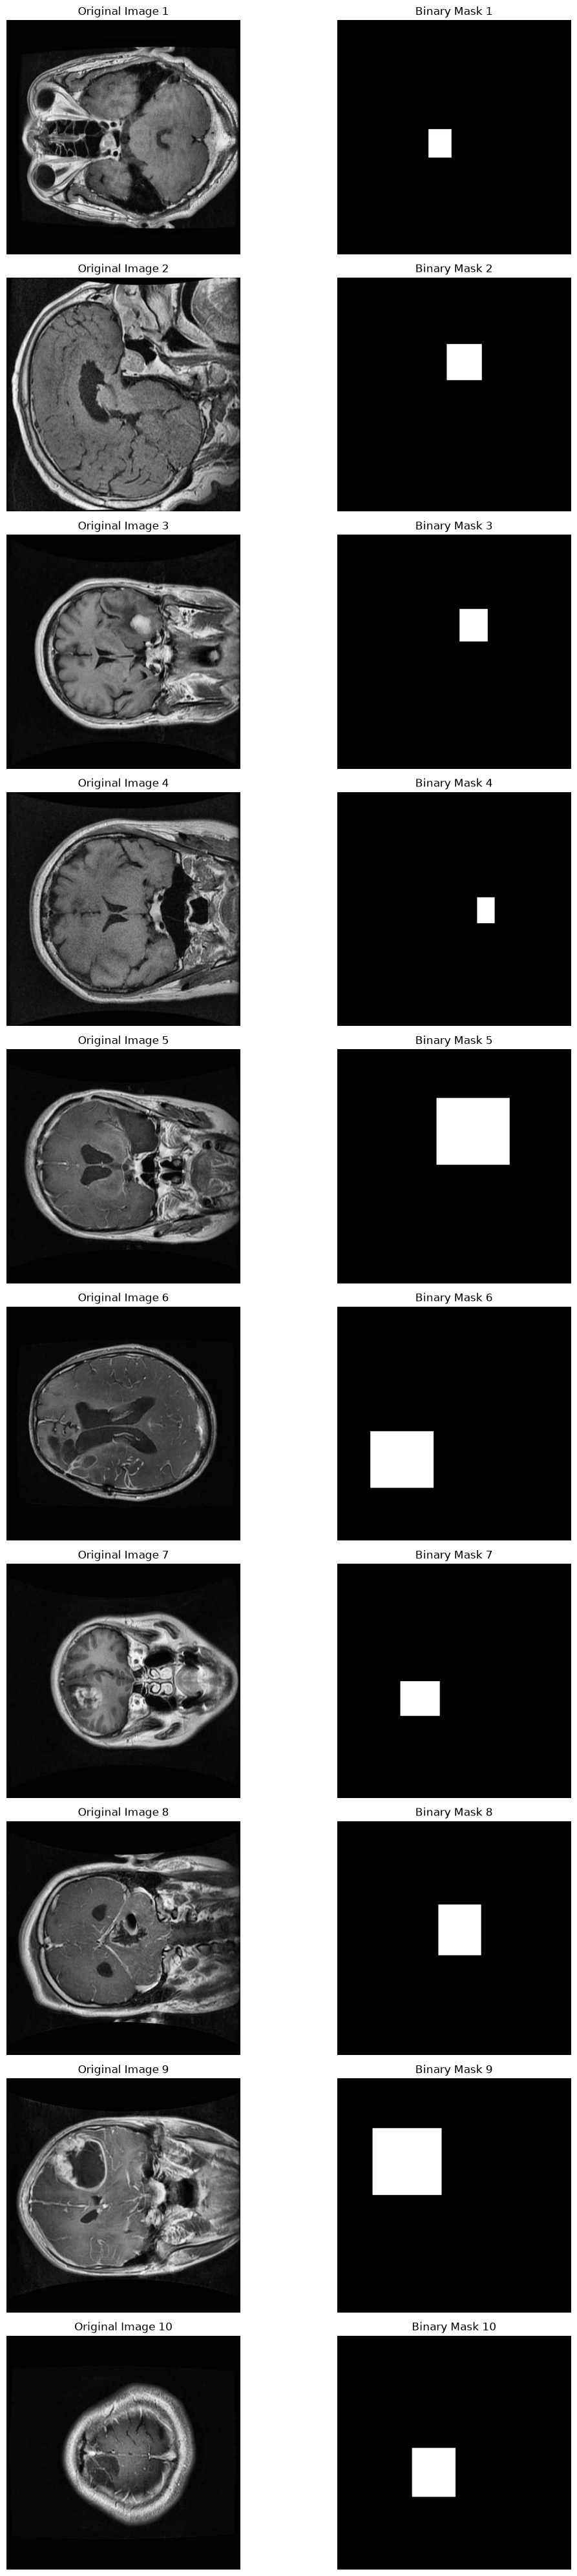

In [4]:
import random

# Select 10 random images
random.seed(42)
selected_images = random.sample(images, 10)

# Group annotations by image ID
annotations_by_image = {}

for annotation in annotations:
    image_id = annotation["image_id"]

    if image_id not in annotations_by_image:
        annotations_by_image[image_id] = []

    annotations_by_image[image_id].append(annotation)

# Create a figure with 10 rows and 2 columns
fig, axes = plt.subplots(10, 2, figsize=(12, 40))

for i, image_info in enumerate(selected_images):

    # Load original image
    image_path = TRAIN_DIR / image_info["file_name"]
    image = Image.open(image_path).convert("RGB")

    # Get corresponding annotations
    image_annotations = annotations_by_image.get(
        image_info["id"], []
    )

    # Generate binary mask
    mask = create_binary_mask(image_info, image_annotations)

    # Verify that image and mask have the same dimensions
    assert mask.shape == (image.height, image.width)

    # Display original image
    axes[i, 0].imshow(image)
    axes[i, 0].set_title(f"Original Image {i + 1}")
    axes[i, 0].axis("off")

    # Display binary mask
    axes[i, 1].imshow(mask, cmap="gray", vmin=0, vmax=1)
    axes[i, 1].set_title(f"Binary Mask {i + 1}")
    axes[i, 1].axis("off")

plt.tight_layout()
plt.show()